In [9]:
# Section 1: Newtwork Synchronization
"""
Coupled FitzHugh-Hagumo Model - N biophysically-motivated oscillators,
diffusively coupled through their voltage-like variable v 
(this is the standard way to model electrical/gap-junction 
coupling between neurons: current flows proportional to the 
voltage DIFFERENCE between connected cells). 
This is close to the actual biophysics.

Kuramoto Model — a much more abstract model where each oscillator is 
reduced to JUST a phase (no amplitude, no separate excitability dynamics).
It's the canonical model in synchronization theory because it's simple 
enough to reason about analytically, and it's what most of the 
"EEG mu/beta synchronization" BCI literature implicitly draws on conceptually. 
Comparing the two is the point of this stage: you'll see the SAME qualitative
phenomenon (coupling strength -> synchrony) emerge from a detailed
biophysical model and a minimal abstract one.


"""

import numpy as np

A_DEFAULT = 0.7
B_DEFAULT = 0.8
EPS_DEFAULT = 0.08

def all_to_all_adjacency(N):
    """
    Parameters
    ----------
    N : the amount of neurons

    Returns
    -------
    A matrix of 1's size N besides its main diagonal.
    Demonstrates that all neurons are synchronized.
    """
    
    all_to_all_matrix = np.ones((N, N)) - np.identity(N)
    return all_to_all_matrix



def ring_adjacency(N):
    """
    Parameters
    ----------
    N : the amount of neurons

    Returns
    -------
    A matrix of 1's above and below it's main diagonal
    of size N. Everywhere else, it's zero. Demonstrates
    that each neuron is synchronized with the neuron
    to the left and to the right of it.
    """
    
    ring_matrix = np.eye(N, N, k = 1) + np.eye(N, N, k = -1) + np.eye(N, N, k = N - 1) + np.eye(N, N, k = -N + 1)
    return ring_matrix



def coupled_fhn_derivatives(state, t, I_func, K, matr, a=A_DEFAULT, b=B_DEFAULT, eps=EPS_DEFAULT):
    """
    Parameters
    ----------
    state = [v_1, v_2, v_3 ... v_n, w_1, w_2, w_3 ... w_n]
    t : float, current time in ms
    I_func : callable, I_func(t) -> injected current (constant is fine —
             pass e.g. `lambda t: 0.5` for a fixed-current bifurcation study)
             Matches the generic deriv_func(state, t) interface after currying I_func,
    K : Coupling Strength (synchronization)
    matr : the Adjancency Matrix that shows the sychronization of neurons
    a, b, eps — henomenological parameters of the FitzHugh-Nagumo model.


    Returns
    -------
    np.ndarray, d(state)/dt
    """

    n = len(state)//2
    v = state[:n]
    w = state[n:]

    if np.isscalar(I_func(t)):
        I_inj = np.full(n,I_func(t))
    else:
        I_inj = np.asarray(I_func(t))

    degree = matr.sum(axis=1)
    dot_product = matr @ v

    dvdt = v - (v**3)/3 - w + I_inj + K * (dot_product - degree * v)
    dwdt = eps * (v + a - b*w)    
    return np.concatenate((dvdt, dwdt))



def kuramoto_derivatives(state, freq, K, matr):
    """
    Parameters
    ----------
    state = [theta_1, theta_2, theta_3 ... theta_n]
    freq = [freq_1, freq_2, freq_3 ... freq_n]
    K : Coupling Strength (synchronization)
    matr : the Adjancency Matrix that shows the sychronization of neurons


    Returns
    -------
    np.ndarray, d(state)/dt
    """

    n = len(state)
    dthetadt = freq + (K / n) * np.sum(matr * (np.sin(state[np.newaxis,:] - state[:,np.newaxis])),axis=1)

    return dthetadt



def kuramoto_order_parameters(state):
    """
    Parameters
    ----------
    state = [theta_1, theta_2, theta_3 ... theta_n]

    Returns
    -------
    r (order parameter)

    """
    complex_phases = np.exp(1j * state)
    average_vector = np.mean(complex_phases)
    r = np.abs(average_vector)
    return r


In [515]:
# Section 1.1: Tests
"""
Tests to might sure the functions work right.
"""


import os
import sys

# 1. Move up two levels to the project root, then point to 'src'
src_path = os.path.abspath(os.path.join('..', '..', 'src'))

# 2. Add 'src' to the Python path if it isn't already there
if src_path not in sys.path:
    sys.path.insert(0, src_path)

# 3. Now you can safely import your module
from hh_model.integrators import rk4_integrate

def test_kuramoto_order_parameter_is_one_for_identical_phases():
    """If every oscillator has the exact same phase, r must be exactly 1."""
    state = np.full(5,10)
    r = kuramoto_order_parameters(state)
    assert np.isclose(r,1)

def test_kuramoto_order_parameter_is_bounded():
    """r is defined as a magnitude of an average of unit vectors — must lie in [0, 1] for any input."""
    state = np.random.rand(10)
    r = kuramoto_order_parameters(state)
    assert 0 - np.exp(-8) < r < 1 + np.exp(-8)

def test_uncoupled_fhn_oscillators_do_not_synchronize_their_currents():
    """With K=0, coupled_fhn_derivatives should reduce to two INDEPENDENT FHN oscillators — verify the coupling term truly vanishes."""
    state = np.random.rand(10)
    uncoupled_state = coupled_fhn_derivatives(state, 0.0, lambda t: 1.3, 0.0, ring_adjacency(5), a=A_DEFAULT, b=B_DEFAULT, eps=EPS_DEFAULT)
    n = len(state)//2
    v = state[:n]
    w = state[n:]
    dvdt = v - (v**3)/3 - w + 1.3
    assert np.allclose(uncoupled_state[:n],dvdt)

def test_strong_kuramoto_coupling_increases_synchrony():
    """For a fixed set of heterogeneous natural frequencies, stronger coupling should produce higher final synchrony than weak coupling — the core qualitative claim of the whole stage."""
    random = np.random.default_rng(1)
    # ensures system starts in a state of complete disorder (incoherence). 
    # At timestamp t=0, the oscillators are scattered evenly in all directions around the circle,
    # meaning their net alignment (the order parameter R) will start very close to 0.0
    state = random.uniform(0, 2 * np.pi, size=5) 
    freq = random.normal(1.0, 0.3, size=5)
    t_array = np.linspace(0,50,1000)

    deriv_func = lambda state,t: kuramoto_derivatives(state, freq, 0.1, all_to_all_adjacency(5))
    weak = rk4_integrate(deriv_func, state, t_array)

    weak_synchrony = kuramoto_order_parameters(weak)

    deriv_func1 = lambda state,t: kuramoto_derivatives(state, freq, 0.5, all_to_all_adjacency(5))
    strong = rk4_integrate(deriv_func1, state, t_array)

    strong_synchrony = kuramoto_order_parameters(strong)

    assert strong_synchrony > weak_synchrony

def test_ring_adjacency_has_correct_degree():
    """Each node in a ring should have exactly 2 neighbors."""
    adjancy = ring_adjacency(5)
    columns = np.sum(adjancy, axis = 1)
    assert np.all(columns == 2.0)
    


test_kuramoto_order_parameter_is_one_for_identical_phases()
test_kuramoto_order_parameter_is_bounded()
test_uncoupled_fhn_oscillators_do_not_synchronize_their_currents()
test_strong_kuramoto_coupling_increases_synchrony()
test_ring_adjacency_has_correct_degree()


In [516]:
# Section 2: Plots

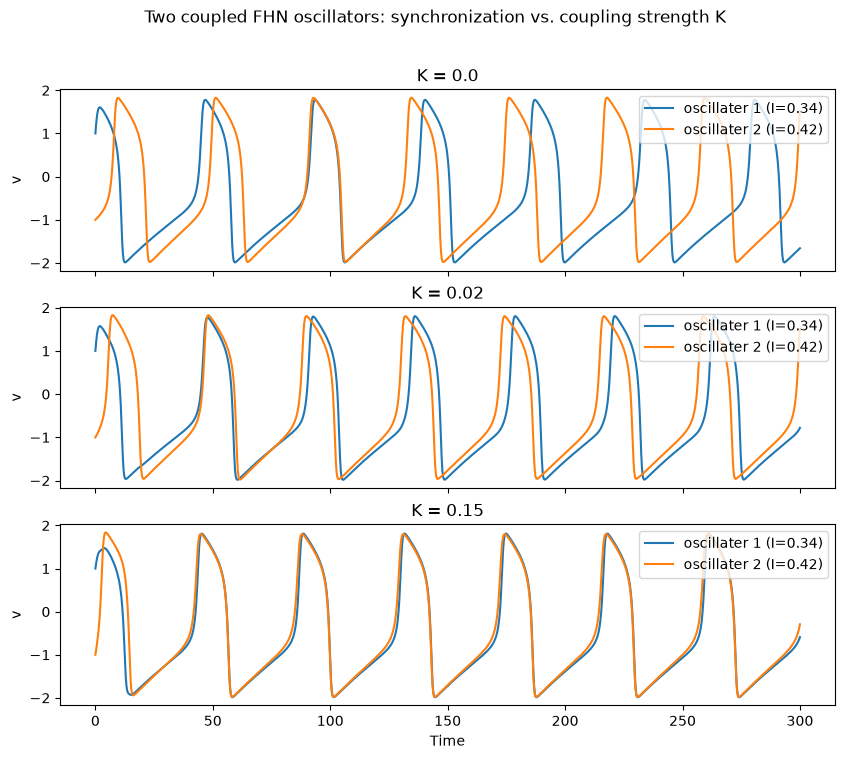

In [556]:
# -----------------------------------------------------------------------
# FIGURE 1: Two coupled FHN oscillators, a few coupling strengths
# -----------------------------------------------------------------------
import matplotlib.pyplot as plt
I_array = np.array([0.34, 0.42])
t_array = np.linspace(0,300,1000)
adj_matr = all_to_all_adjacency(2)
state0 = np.array([1,-1, 0.3, -0.3])
K_array = np.array([0.0,0.02,0.15])

fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fig.suptitle("Two coupled FHN oscillators: synchronization vs. coupling strength K")
for index,K in enumerate(K_array):
    deriv_func = lambda state,t: coupled_fhn_derivatives(state, t, lambda t: I_array, K, adj_matr, a=A_DEFAULT, b=B_DEFAULT, eps=EPS_DEFAULT)
    v = rk4_integrate(deriv_func, state0, t_array)
    ax[index].plot(t_array, v[:,0], label = "oscillater 1 (I=0.34)")
    ax[index].plot(t_array, v[:,1], label = "oscillater 2 (I=0.42)")
    ax[index].set_title("K = " + str(K))
    ax[index].set_ylabel("v")
    ax[index].legend(loc = 'upper right')

plt.xlabel("Time")
plt.show()